# Case study 3: Nested sampling with a `harv` model

This notebook produces the figure and the numbers for Case study 3 of the paper. We extract the log prior and log likelihood functions from the `numpyro` model that `harv` builds, and run the nested slice sampler from `blackjax` (`blackjax.nss`) on the same model and prior. We compare the results with those from the rejection sampler: the evidence (fully marginalized likelihood) $\ln p(\boldsymbol{y})$, and, for a source whose posterior pdf has many period modes, the posterior samples and the time each method takes to produce them, also with ten times more live points.

We use four of the six APOGEE sources from Case study 1 (`apogee-pipeline.ipynb`), with the same data, prior and model: three for which the rejection sampling with $10^7$ prior samples resolves the posterior pdf ($J_{\rm eff} \gg 1$), one of which has many period modes, and one for which a single sample survives even with $10^8$ prior samples ($J_{\rm eff} \approx 1$). For the last, we also run MCMC from the single sample of the run with $10^7$ prior samples, to compare with Case study 1. This notebook writes the figure `../paper/figures/cs3-nested-sampling.pdf` and prints the numbers quoted in the text. All seeds are fixed.

In [1]:
import jax
import numpyro

# Enable float64 before importing harv:
jax.config.update("jax_enable_x64", True)
numpyro.set_host_device_count(4)  # for the MCMC chains

In [2]:
import time
import warnings
from pathlib import Path

import astropy.table as at
import blackjax
import blackjax.ns.utils as nsu
import harv
import harv.models as hm
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from jax.scipy.special import logsumexp
from matplotlib.ticker import NullFormatter, ScalarFormatter
from numpyro.diagnostics import print_summary
from numpyro.handlers import block
from numpyro.infer import Predictive
from numpyro.infer.util import (
    constrain_fn,
    log_likelihood,
    potential_energy,
    unconstrain_fn,
)
from unxt import Q

%matplotlib inline
print(
    f"harv {harv.__version__}, jax {jax.__version__}, numpyro {numpyro.__version__}, "
    f"blackjax {blackjax.__version__}"
)
print(jax.devices())

harv 0.0.2.dev238+g4d7e5d20a, jax 0.12.0.1, numpyro 0.22.0, blackjax 1.7.1
[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]


In [3]:
repo_path = Path("..").resolve()
data_path = repo_path / "data" / "apogee"
figure_path = repo_path / "paper" / "figures"
figure_path.mkdir(exist_ok=True)

## Data, prior and model

These are the same as in Case study 1: the visit velocities with the recalibrated uncertainties, in km/s, and the same prior. Note that the evidence is a density in the data, so its value depends on the velocity unit.

We use three sources with $J_{\rm eff} \gg 1$, one of which has samples in many period modes, and one with $J_{\rm eff} \approx 1$:

In [4]:
SOURCES = [
    "2M02323271+3350542",  # 3 visits: many samples, J_eff >> 1
    "2M16022747+2902099",  # 12 visits: many samples, J_eff >> 1
    "2M15323868+4218297",  # 3 visits: many samples in many period modes, J_eff >> 1
    "2M20183197+1953430",  # 13 visits: one sample, unimodal in period, J_eff ~ 1
]

rv_data = {}
for path in sorted(data_path.glob("*.ecsv")):
    tbl = at.Table.read(path)
    rv_data[tbl.meta["APOGEE_ID"]] = harv.RVData(
        time=Q(tbl["jd"], "day"),
        rv=Q(tbl["rv"], "km/s"),
        rv_err=Q(tbl["rv_err"], "km/s"),
    )

sigma_K0, sigma_v0 = 30.0, 150.0  # km/s
prior = hm.StandardRV().default_prior(
    period_min=Q(2.0, "day"),
    period_max=Q(16384.0, "day"),
    sigma_K0=Q(sigma_K0, "km/s"),
    sigma_v0=Q(sigma_v0, "km/s"),
    eccentricity=dist.TruncatedNormal(0.5, 0.25, low=0.0, high=1.0),
)
model = harv.RVModel()
sampler = harv.RejectionSampler(prior, model)

## Rejection sampling

We repeat the rejection sampling with five independent libraries of $J = 10^7$ prior samples, each shared by the four sources as in Case study 1. The library from key 0 is the one from Case study 1, so the first run reproduces the results there (the evidence depends only on the prior samples and the data, not on the key used for the rejection step). The first run for each source includes the compilation time. We also time the drawing of each library. We keep the samples from the first run, and from all five runs for 2M15323868+4218297.

In [5]:
# The J_eff ~ 1 source warns that the run is under-resolved, which we know.
warnings.filterwarnings("ignore", message="Under-resolved rejection run")


def evidence_row(apogee_id, k, s, t0):
    meta = s.metadata
    return {
        "APOGEE_ID": apogee_id,
        "J": int(meta["n_prior_samples"]),
        "key": k,
        "ln_Z": float(meta["ln_Z_int"]),
        "mcse": float(meta["ln_Z_int_mcse"]),
        "J_eff": float(meta["ln_Z_int_ess"]),
        "max_ln_L": float(meta["max_ln_likelihood"]),
        "M": s.n_samples,
        "time": time.perf_counter() - t0,
    }


J = 10_000_000
rows, first_run, multimodal_runs, library_time = [], {}, [], []
for k in range(5):
    t0 = time.perf_counter()
    prior_samples = jax.block_until_ready(
        prior.sample(J, key=jax.random.key(k), model=model)
    )
    library_time.append(time.perf_counter() - t0)
    for apogee_id in SOURCES:
        t0 = time.perf_counter()
        s = sampler.run_with_samples(
            rv_data[apogee_id],
            prior_samples,
            key=jax.random.key(100 + k),
            return_evidence_stats=True,
        )
        rows.append(evidence_row(apogee_id, k, s, t0))
        if k == 0:
            first_run[apogee_id] = s
        if apogee_id == SOURCES[2]:
            multimodal_runs.append(s)
print(
    f"{np.median(library_time[1:]):.1f} s to draw each library of {J:.0e} prior "
    "samples (after the first)"
)

0.4 s to draw each library of 1e+07 prior samples (after the first)


For 2M20183197+1953430, a single sample survives, so Case study 1 reruns the rejection sampling with $J = 10^8$ new prior samples (`sampler.run` with key 10, which draws the prior samples itself) and uses that run in the rest of the analysis. We repeat that run here.

In [6]:
apogee_id = SOURCES[3]
t0 = time.perf_counter()
s = sampler.run(
    rv_data[apogee_id],
    key=jax.random.key(10),
    n_prior_samples=10 * J,
    return_evidence_stats=True,
)
rows.append(evidence_row(apogee_id, 0, s, t0))
print(f"{apogee_id}, J = {10 * J:.0e}: P = {s['period'].to_value('day')} d")
rejection = at.Table(rows=rows)

2M20183197+1953430, J = 1e+08: P = [51.28651057] d


In [7]:
def cs1_run(apogee_id):
    """The run that Case study 1 uses: the first with the largest number of prior samples."""
    r = rejection[rejection["APOGEE_ID"] == apogee_id]
    return r[r["J"] == r["J"].max()][0]


for apogee_id in SOURCES:
    r = rejection[rejection["APOGEE_ID"] == apogee_id]
    for J_run in np.unique(r["J"]):
        g = r[r["J"] == J_run]
        line = (
            f"{apogee_id}, J = {J_run:.0e}: first run {g['ln_Z'][0]:.4f} ± {g['mcse'][0]:.4f} "
            f"(J_eff = {g['J_eff'][0]:.3g}, {g['M'][0]} samples, max ln L {g['max_ln_L'][0]:.2f})"
        )
        if len(g) > 1:
            line += (
                f"\n  five runs: std {g['ln_Z'].std(ddof=1):.4f}, "
                f"median MCSE {np.median(g['mcse']):.4f}, "
                f"{np.median(g['time'][1:]):.1f} s per run after the first"
            )
        print(line)

2M02323271+3350542, J = 1e+07: first run -8.4890 ± 0.0005 (J_eff = 2.75e+06, 1353840 samples, max ln L -6.49)
  five runs: std 0.0003, median MCSE 0.0005, 2.0 s per run after the first
2M16022747+2902099, J = 1e+07: first run -6.2214 ± 0.0022 (J_eff = 2.06e+05, 40742 samples, max ln L -0.71)
  five runs: std 0.0020, median MCSE 0.0022, 1.9 s per run after the first
2M15323868+4218297, J = 1e+07: first run -17.7285 ± 0.0074 (J_eff = 1.84e+04, 9104 samples, max ln L -10.74)
  five runs: std 0.0038, median MCSE 0.0074, 1.6 s per run after the first
2M20183197+1953430, J = 1e+07: first run -328.5305 ± 1.0000 (J_eff = 1, 1 samples, max ln L -312.41)
  five runs: std 149.7604, median MCSE 1.0000, 2.0 s per run after the first
2M20183197+1953430, J = 1e+08: first run -134.1164 ± 1.0000 (J_eff = 1, 1 samples, max ln L -115.70)


## Log prior and log likelihood for the nested sampler

`model.numpyro_model(...)` returns the `numpyro` model that `harv`'s MCMC sampler runs: each nonlinear parameter is a `numpyro.sample` site, and the marginal log likelihood enters as a single `numpyro.factor` site named `"ln_lik"`. The nested sampler needs the log prior and the log likelihood of a single particle separately, and a set of initial live points drawn from the prior. We get all three from the model with `numpyro` utilities, in `numpyro`'s unconstrained space, where each parameter is mapped to the real line (for the period, this map is close to $\ln P$ except near the limits of the prior):

- the prior model is the model with the `"ln_lik"` site hidden;
- the log prior is minus its potential energy, which includes the log-Jacobian of the map from the unconstrained space;
- the log likelihood is the value of the `"ln_lik"` site;
- the initial live points are prior draws of the prior model, mapped to the unconstrained space.

We stop when the evidence in the live points is below $10^{-3}$ of the accumulated evidence, and we estimate $\ln p(\boldsymbol{y})$ and its uncertainty within one run from 100 simulated sequences of prior volumes.

In [8]:
def nested_sampler(numpyro_model, n_live=1000, num_inner_steps=20):
    prior_model = block(numpyro_model, hide=["ln_lik"])

    def constrain(u):
        return constrain_fn(prior_model, (), {}, u)

    def log_prior(u):
        return -potential_energy(prior_model, (), {}, u)

    def log_lik(u):
        return log_likelihood(numpyro_model, constrain(u), batch_ndims=0)["ln_lik"]

    # Replace a tenth of the live points per iteration (100 for 1000 live points).
    algo = blackjax.nss(
        log_prior,
        log_lik,
        num_inner_steps=num_inner_steps,
        num_delete=n_live // 10,
    )
    step = jax.jit(algo.step)

    def run(key):
        init_key, weight_key, sample_key, key = jax.random.split(key, 4)
        t0 = time.perf_counter()
        draws = Predictive(prior_model, num_samples=n_live)(init_key)
        state = algo.init(
            jax.vmap(lambda p: unconstrain_fn(prior_model, (), {}, p))(draws)
        )
        dead = []
        while state.integrator.logZ_live - state.integrator.logZ >= np.log(1e-3):
            key, subkey = jax.random.split(key)
            state, info = step(subkey, state)
            dead.append(info)
        assert np.isfinite(state.integrator.logZ) and np.isfinite(
            state.integrator.logZ_live
        )
        final = nsu.finalise(state, dead)
        log_w = nsu.log_weights(weight_key, final, shape=100)
        ln_Z = logsumexp(log_w, axis=0)
        # The information (KL divergence of the posterior from the prior), for each
        # simulated sequence of prior volumes.
        loglik = final.particles.loglikelihood[:, None]
        H = jnp.sum(jnp.exp(log_w - ln_Z) * loglik, axis=0) - ln_Z
        # Weights of the dead points for one simulated sequence of prior volumes.
        weight = jnp.exp(log_w[:, 0] - ln_Z[0])
        slices = final.update_info
        best = jnp.argmax(final.particles.loglikelihood)
        best_u = jax.tree.map(lambda x: x[best], final.particles.position)
        return {
            "ln_Z": float(ln_Z.mean()),
            "ln_Z_err": float(ln_Z.std()),
            "H": float(H.mean()),
            "ess": float(1 / jnp.sum(weight**2)),
            "dead": jax.vmap(constrain)(final.particles.position),
            "weight": weight,
            "n_iter": len(dead),
            # Each slice step evaluates the two bracket ends, then each expansion and shrink.
            "n_eval": n_live
            + int(jnp.sum(2 + slices.num_expansions + slices.num_shrink)),
            "max_ln_L": float(final.particles.loglikelihood[best]),
            "P_max_ln_L": float(constrain(best_u)["period"]),
            "time": time.perf_counter() - t0,
            "posterior": jax.vmap(constrain)(
                nsu.sample(sample_key, final, shape=4096).position
            ),
        }

    return run

### Checks

First, the `"ln_lik"` site must give the same marginal log likelihood as the rejection sampler, to rounding error (the log likelihood of a random prior sample can be very large). Requesting the top 100 of 100 prior samples returns all of them, each with the log likelihood that the rejection sampler computed. Second, the prior draws of the `numpyro` model must follow the same distribution as `harv`'s own prior samples; we compare their quantiles.

We do not run the nested sampler with the likelihood set to zero as a check of the prior normalization: that always returns $\ln p(\boldsymbol{y}) = 0$, whatever the normalization of the prior or the Jacobian. The useful check is the sources with $J_{\rm eff} \gg 1$, for which the rejection estimate is precise: a wrong Jacobian would change the prior pdf that the slice moves sample from, and the two estimates would disagree.

In [9]:
check = prior.sample(100, key=jax.random.key(10), model=model)
for apogee_id in SOURCES:
    data = rv_data[apogee_id]
    s = sampler.run_with_samples(
        data, check, key=jax.random.key(11), top_k=100, return_logprobs=True
    )
    numpyro_model = model.numpyro_model(
        prior.nonlinear_priors, data, prior.linear_priors
    )
    params = {name: s[name].value for name in s.nonlinear}
    diff = np.abs(log_likelihood(numpyro_model, params)["ln_lik"] - s.ln_likelihood)
    print(
        f"{apogee_id}: max |difference| = {diff.max():.1e}, "
        f"relative {np.max(diff / np.abs(s.ln_likelihood)):.1e}"
    )

q = [1, 16, 50, 84, 99]
draws = Predictive(block(numpyro_model, hide=["ln_lik"]), num_samples=100_000)(
    jax.random.key(12)
)
ref = prior.sample_nonlinear(100_000, key=jax.random.key(13))
for name in s.nonlinear:
    print(
        f"{name}: numpyro {np.percentile(draws[name], q).round(3)}, "
        f"harv {np.percentile(ref[name], q).round(3)}"
    )

2M02323271+3350542: max |difference| = 6.0e-12, relative 6.8e-13
2M16022747+2902099: max |difference| = 2.3e-10, relative 3.2e-11
2M15323868+4218297: max |difference| = 5.1e-09, relative 3.1e-13
2M20183197+1953430: max |difference| = 4.2e-09, relative 4.8e-14
period: numpyro [2.1780000e+00 8.5800000e+00 1.7976100e+02 3.8944590e+03 1.4946298e+04], harv [2.1890000e+00 8.5140000e+00 1.8018600e+02 3.8408470e+03 1.4924408e+04]
eccentricity: numpyro [0.038 0.268 0.501 0.733 0.961], harv [0.039 0.269 0.501 0.732 0.963]
phase_peri: numpyro [0.01  0.161 0.499 0.839 0.99 ], harv [0.01  0.159 0.5   0.839 0.99 ]
arg_peri: numpyro [0.062 0.996 3.144 5.29  6.222], harv [0.064 1.009 3.144 5.287 6.216]


## Nested sampling

For each source, we run the nested slice sampler with 1000 live points, 20 slice steps per new point (5 times the number of parameters), and 100 points (a tenth of the live points) replaced per iteration, with five seeds. We also compute the information $H = \int p(\boldsymbol{\theta} \mid \boldsymbol{y}) \ln[p(\boldsymbol{\theta} \mid \boldsymbol{y}) / p(\boldsymbol{\theta})]\,{\rm d}\boldsymbol{\theta}$ (in nats) from the weights of the dead points, the effective sample size of the weighted dead points, $1/\sum_i w_i^2$ for normalized weights $w_i$, count the likelihood evaluations, and record the period of the point with the largest likelihood. The first run for each source includes the compilation time.

In [10]:
ns, ns_ln_Z = {}, {}
for apogee_id in SOURCES:
    run = nested_sampler(
        model.numpyro_model(
            prior.nonlinear_priors, rv_data[apogee_id], prior.linear_priors
        )
    )
    ns[apogee_id] = [run(jax.random.key(seed)) for seed in range(5)]
    ns_ln_Z[apogee_id] = np.array([x["ln_Z"] for x in ns[apogee_id]])
    for seed, x in enumerate(ns[apogee_id]):
        print(
            f"{apogee_id} seed {seed}: ln Z = {x['ln_Z']:.4f} ± {x['ln_Z_err']:.4f}, H = {x['H']:.2f}, ESS {x['ess']:.0f}, "
            f"{x['n_iter']} iterations, {x['n_eval']:.3g} evaluations, "
            f"max ln L = {x['max_ln_L']:.2f} at P = {x['P_max_ln_L']:.2f} d, {x['time']:.1f} s"
        )

2M02323271+3350542 seed 0: ln Z = -8.5431 ± 0.0344, H = 1.04, ESS 2355, 85 iterations, 1.14e+06 evaluations, max ln L = -6.49 at P = 253.50 d, 7.9 s
2M02323271+3350542 seed 1: ln Z = -8.4890 ± 0.0334, H = 1.05, ESS 2253, 85 iterations, 1.15e+06 evaluations, max ln L = -6.49 at P = 326.07 d, 1.7 s
2M02323271+3350542 seed 2: ln Z = -8.4868 ± 0.0332, H = 1.04, ESS 2186, 85 iterations, 1.15e+06 evaluations, max ln L = -6.49 at P = 185.20 d, 1.7 s
2M02323271+3350542 seed 3: ln Z = -8.5026 ± 0.0369, H = 1.08, ESS 2213, 85 iterations, 1.16e+06 evaluations, max ln L = -6.49 at P = 544.64 d, 1.7 s
2M02323271+3350542 seed 4: ln Z = -8.4593 ± 0.0342, H = 1.04, ESS 2174, 85 iterations, 1.16e+06 evaluations, max ln L = -6.49 at P = 306.08 d, 1.7 s
2M16022747+2902099 seed 0: ln Z = -6.1168 ± 0.0590, H = 3.17, ESS 3249, 116 iterations, 1.67e+06 evaluations, max ln L = -0.72 at P = 2129.26 d, 10.1 s
2M16022747+2902099 seed 1: ln Z = -6.3152 ± 0.0601, H = 3.32, ESS 3337, 118 iterations, 1.73e+06 evalua

In [11]:
for apogee_id in SOURCES:
    ln_Z, r = ns_ln_Z[apogee_id], cs1_run(apogee_id)
    g = rejection[(rejection["APOGEE_ID"] == apogee_id) & (rejection["J"] == r["J"])]
    t_rej = np.median(g["time"][1:]) if len(g) > 1 else g["time"][0]
    times = np.array([x["time"] for x in ns[apogee_id]])
    n_eval = np.array([x["n_eval"] for x in ns[apogee_id]])
    H = np.mean([x["H"] for x in ns[apogee_id]])
    P = ns[apogee_id][0]["posterior"]["period"]
    print(
        f"{apogee_id}: nested sampling {ln_Z.mean():.4f} ± {ln_Z.std(ddof=1):.4f} (five seeds); "
        f"Case study 1 run (J = {r['J']:.0e}) {r['ln_Z']:.4f} ± {r['mcse']:.4f}, "
        f"difference {r['ln_Z'] - ln_Z.mean():.4f}\n"
        f"  {np.median(times[1:]):.1f} s per run after the first "
        f"(compilation ~{times[0] - np.median(times[1:]):.0f} s)\n"
        f"  P percentiles {q}: {np.percentile(P, q)} d\n"
        f"  H = {H:.2f}: J_eff / J = {r['J_eff'] / r['J']:.2g} <= exp(-H) = {np.exp(-H):.2g}\n"
        f"  time per likelihood evaluation: rejection {t_rej / r['J'] * 1e6:.2f} us, "
        f"nested sampling {np.median(times[1:] / n_eval[1:]) * 1e6:.2f} us"
    )

2M02323271+3350542: nested sampling -8.4961 ± 0.0306 (five seeds); Case study 1 run (J = 1e+07) -8.4890 ± 0.0005, difference 0.0072
  1.7 s per run after the first (compilation ~6 s)
  P percentiles [1, 16, 50, 84, 99]: [   19.4731699    777.91651366  2591.62776925  6548.28463593
 14524.39966764] d
  H = 1.05: J_eff / J = 0.28 <= exp(-H) = 0.35
  time per likelihood evaluation: rejection 0.20 us, nested sampling 1.48 us
2M16022747+2902099: nested sampling -6.2431 ± 0.0861 (five seeds); Case study 1 run (J = 1e+07) -6.2214 ± 0.0022, difference 0.0217
  7.0 s per run after the first (compilation ~3 s)
  P percentiles [1, 16, 50, 84, 99]: [  974.44504005  3768.24994897  9121.29829111 13922.16315851
 16201.42363937] d
  H = 3.27: J_eff / J = 0.021 <= exp(-H) = 0.038
  time per likelihood evaluation: rejection 0.19 us, nested sampling 4.16 us
2M15323868+4218297: nested sampling -17.7396 ± 0.0685 (five seeds); Case study 1 run (J = 1e+07) -17.7285 ± 0.0074, difference 0.0111
  3.5 s per run 

## Nested sampling without the analytic marginalization

For the first two sources, we also run the nested sampler on the model without the analytic marginalization (`marginalized=False`), in which the velocity semi-amplitude and the systemic velocity are sampled explicitly from their prior pdfs (the prior scale for the semi-amplitude depends on the period and eccentricity). This model has six parameters, so we use 30 slice steps per new point. The evidence should agree with the marginalized model, which checks the marginalization independently.

In [12]:
for apogee_id in SOURCES[:2]:
    run = nested_sampler(
        model.numpyro_model(
            prior.nonlinear_priors,
            rv_data[apogee_id],
            prior.linear_priors,
            marginalized=False,
        ),
        num_inner_steps=30,
    )
    ln_Z = np.array([run(jax.random.key(seed))["ln_Z"] for seed in range(3)])
    ln_Z_marg = ns_ln_Z[apogee_id]
    print(
        f"{apogee_id}: not marginalized {ln_Z.mean():.4f} ± {ln_Z.std(ddof=1):.4f} (three seeds), "
        f"marginalized {ln_Z_marg.mean():.4f} ± {ln_Z_marg.std(ddof=1):.4f}"
    )

2M02323271+3350542: not marginalized -8.6110 ± 0.0887 (three seeds), marginalized -8.4961 ± 0.0306
2M16022747+2902099: not marginalized -6.2633 ± 0.1700 (three seeds), marginalized -6.2431 ± 0.0861


### MCMC from the run with $10^7$ prior samples for 2M20183197+1953430

In Case study 1, the run with $10^8$ prior samples moves the single sample for this source to a different period mode, where MCMC converges with a good fit at the MAP sample. The nested sampling posterior above is in the same mode. Here we run MCMC from the single sample of the run with $10^7$ prior samples instead, with the same settings as in Case study 1, to see what happens without the larger run.

In [13]:
apogee_id = SOURCES[3]
data, init = rv_data[apogee_id], first_run[apogee_id]
print(f"Initial sample: P = {init['period'].to_value('day')} d")
s = harv.NumpyroSampler(prior, model).run(
    data,
    init_samples=init,
    key=jax.random.key(104),  # the key that Case study 1 uses for this source
    num_chains=4,
    num_warmup=1000,
    num_samples=2000,
    return_logprobs=True,
)
# wrap_angles makes K positive; Samples stores the chains one after another.
w, names = s.wrap_angles(), [*s.nonlinear, *s.linear]
print_summary({name: np.asarray(w[name].value).reshape(4, -1) for name in names})

m = s.map_sample()
print(
    f"MAP sample: P = {m['period'].to_value('day').item():.4f} d, "
    f"ln L = {m.ln_likelihood.item():.2f}, "
    f"chi2 = {m.chi2(data, model).item():.1f} for {data.rv.shape[0]} visits"
)

Initial sample: P = [55.24399962] d


  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]


                    mean       std    median      5.0%     95.0%     n_eff     r_hat
        period     55.21      0.00     55.21     55.20     55.21   7680.47      1.00
  eccentricity      0.10      0.00      0.10      0.10      0.10   6082.46      1.00
    phase_peri      0.85      0.01      0.85      0.84      0.85   5610.26      1.00
      arg_peri      1.86      0.03      1.86      1.80      1.91   5661.49      1.00
    rv_semiamp     34.08      0.11     34.08     33.89     34.26   7414.49      1.00
         v_sys     -4.08      0.06     -4.08     -4.18     -3.97   7694.08      1.00

MAP sample: P = 55.2090 d, ln L = -212.79, chi2 = 418.2 for 13 visits


## Posterior samples for 2M15323868+4218297

This source has three visits over 26 days. Its posterior pdf has many period modes between 2 and about 100 days, but $J_{\rm eff} \gg 1$, so the rejection samples are independent draws from the posterior pdf that resolve the modes. For this source, we also run the nested sampler with ten times more live points (10,000, with 1000 replaced per iteration), again with five seeds, to see how the results change with the number of live points.

In [14]:
apogee_id = SOURCES[2]
run = nested_sampler(
    model.numpyro_model(
        prior.nonlinear_priors, rv_data[apogee_id], prior.linear_priors
    ),
    n_live=10_000,
)
ns_10k = [run(jax.random.key(seed)) for seed in range(5)]
for seed, x in enumerate(ns_10k):
    print(
        f"10000 live points, seed {seed}: ln Z = {x['ln_Z']:.4f} ± {x['ln_Z_err']:.4f}, "
        f"H = {x['H']:.2f}, ESS {x['ess']:.0f}, {x['n_iter']} iterations, "
        f"{x['n_eval']:.3g} evaluations, {x['time']:.1f} s"
    )

10000 live points, seed 0: ln Z = -17.7653 ± 0.0284, H = 6.12, ESS 22643, 133 iterations, 3.17e+07 evaluations, 38.4 s
10000 live points, seed 1: ln Z = -17.7539 ± 0.0263, H = 6.11, ESS 22843, 133 iterations, 3.16e+07 evaluations, 32.5 s
10000 live points, seed 2: ln Z = -17.7401 ± 0.0270, H = 6.10, ESS 22853, 133 iterations, 3.14e+07 evaluations, 32.6 s
10000 live points, seed 3: ln Z = -17.7467 ± 0.0240, H = 6.11, ESS 22689, 133 iterations, 3.14e+07 evaluations, 32.6 s
10000 live points, seed 4: ln Z = -17.7119 ± 0.0260, H = 6.07, ESS 22813, 132 iterations, 3.08e+07 evaluations, 34.7 s


We compare the fraction of the posterior probability in four ranges of period: below 10 days, the two largest modes (12.5 to 15.5 days and 22.5 to 25.5 days), and above 100 days. For the rejection runs, this is the fraction of the samples. For the nested sampling runs, we use the weighted dead points directly rather than the 4096 posterior draws, which are resampled from them and so add noise. The uncertainty is $\sqrt{f(1-f)/N_{\rm eff}}$ for a fraction $f$, where $N_{\rm eff}$ is the number of samples or the effective sample size of the weights.

The mean over the five rejection runs is our reference. For each number of live points, $\chi^2/N$ is the squared difference of the nested sampling fractions from the reference, divided by the sum of the squared uncertainties of the run and of the reference, averaged over the runs and the ranges of period. It is about 1 if the effective sample size describes the precision of a run. Otherwise, a run is worth about $N_{\rm eff} / (\chi^2/N)$ independent samples. If the scatter of the fractions decreases as $n_{\rm live}^{-1/2}$, $\chi^2/N$ is about the same for both numbers of live points, and the number of independent samples grows in proportion to $n_{\rm live}$.

We also compare the time each method takes to produce its samples, after compilation.

In [15]:
windows = {
    "P < 10 d": (2.0, 10.0),
    "12.5-15.5 d": (12.5, 15.5),
    "22.5-25.5 d": (22.5, 25.5),
    "P > 100 d": (100.0, 16384.0),
}


def window_fractions(P, w):
    """Fraction of the weight in each period window, and its uncertainty."""
    n_eff = w.sum() ** 2 / (w**2).sum()
    f = np.array([w[(P >= a) & (P < b)].sum() for a, b in windows.values()]) / w.sum()
    return f, np.sqrt(f * (1 - f) / n_eff)


print(f"Fraction of the posterior probability in {list(windows)}:")
P_rej = [np.asarray(s["period"].to_value("day")) for s in multimodal_runs]
# Arrays of shape (run, window):
f_rej, err_rej = np.array(
    [window_fractions(P, np.ones_like(P)) for P in P_rej]
).transpose(1, 0, 2)
for k, P in enumerate(P_rej):
    print(
        f"rejection run {k} ({len(P)} samples): {f_rej[k].round(3)} ± {err_rej[k].round(3)}"
    )
print(
    f"  scatter over the runs {f_rej.std(axis=0, ddof=1).round(4)}, "
    f"uncertainty of each run {err_rej.mean(axis=0).round(4)}"
)
ref = f_rej.mean(axis=0)
ref_err = np.sqrt(np.mean(err_rej**2, axis=0) / len(f_rej))

r = rejection[rejection["APOGEE_ID"] == apogee_id]
t_rej, M = np.median(r["time"][1:]), np.median(r["M"])
print(
    f"Rejection: {t_rej:.1f} s per run (after the first) for {M:.0f} independent samples "
    f"({M / t_rej:.0f} per second), plus {np.median(library_time[1:]):.1f} s to draw the "
    "prior samples (shared by all sources)"
)

for n_live, runs in [(1000, ns[apogee_id]), (10_000, ns_10k)]:
    f, err = np.array(
        [
            window_fractions(np.asarray(x["dead"]["period"]), np.asarray(x["weight"]))
            for x in runs
        ]
    ).transpose(1, 0, 2)
    for seed, x in enumerate(runs):
        print(
            f"nested sampling, {n_live} live points, seed {seed} (ESS {x['ess']:.0f}): "
            f"{f[seed].round(3)} ± {err[seed].round(3)}"
        )
    chi2 = np.mean((f - ref) ** 2 / (err**2 + ref_err**2))
    ess = np.median([x["ess"] for x in runs])
    t = np.median([x["time"] for x in runs[1:]])
    n_ind = ess / chi2
    print(
        f"  chi2/N = {chi2:.2f}: each run is worth about {n_ind:.0f} independent samples "
        f"(ESS {ess:.0f})\n"
        f"  {t:.1f} s per run (after the first): {ess / t:.0f} ESS and {n_ind / t:.0f} "
        "independent samples per second\n"
        f"  matching one rejection run would need {M / n_ind:.1f} times as many live points "
        f"({M / n_ind * n_live:.0f}), and {M / n_ind * t / t_rej:.0f} times the time of a "
        "rejection run"
    )

Fraction of the posterior probability in ['P < 10 d', '12.5-15.5 d', '22.5-25.5 d', 'P > 100 d']:
rejection run 0 (9104 samples): [0.335 0.128 0.166 0.018] ± [0.005 0.004 0.004 0.001]
rejection run 1 (9193 samples): [0.327 0.132 0.166 0.016] ± [0.005 0.004 0.004 0.001]
rejection run 2 (8977 samples): [0.338 0.13  0.165 0.017] ± [0.005 0.004 0.004 0.001]
rejection run 3 (9072 samples): [0.333 0.127 0.164 0.016] ± [0.005 0.003 0.004 0.001]
rejection run 4 (9174 samples): [0.338 0.128 0.164 0.019] ± [0.005 0.003 0.004 0.001]
  scatter over the runs [0.0046 0.0021 0.001  0.0011], uncertainty of each run [0.0049 0.0035 0.0039 0.0014]
Rejection: 1.6 s per run (after the first) for 9104 independent samples (5650 per second), plus 0.4 s to draw the prior samples (shared by all sources)
nested sampling, 1000 live points, seed 0 (ESS 2185): [0.317 0.11  0.173 0.048] ± [0.01  0.007 0.008 0.005]
nested sampling, 1000 live points, seed 1 (ESS 2306): [0.314 0.174 0.146 0.02 ] ± [0.01  0.008 0.007 0.

### Figure

The period and eccentricity of 4096 random samples from the first rejection run (the run from Case study 1), and of the 4096 posterior draws from the first nested sampling run with 1000 and with 10,000 live points.

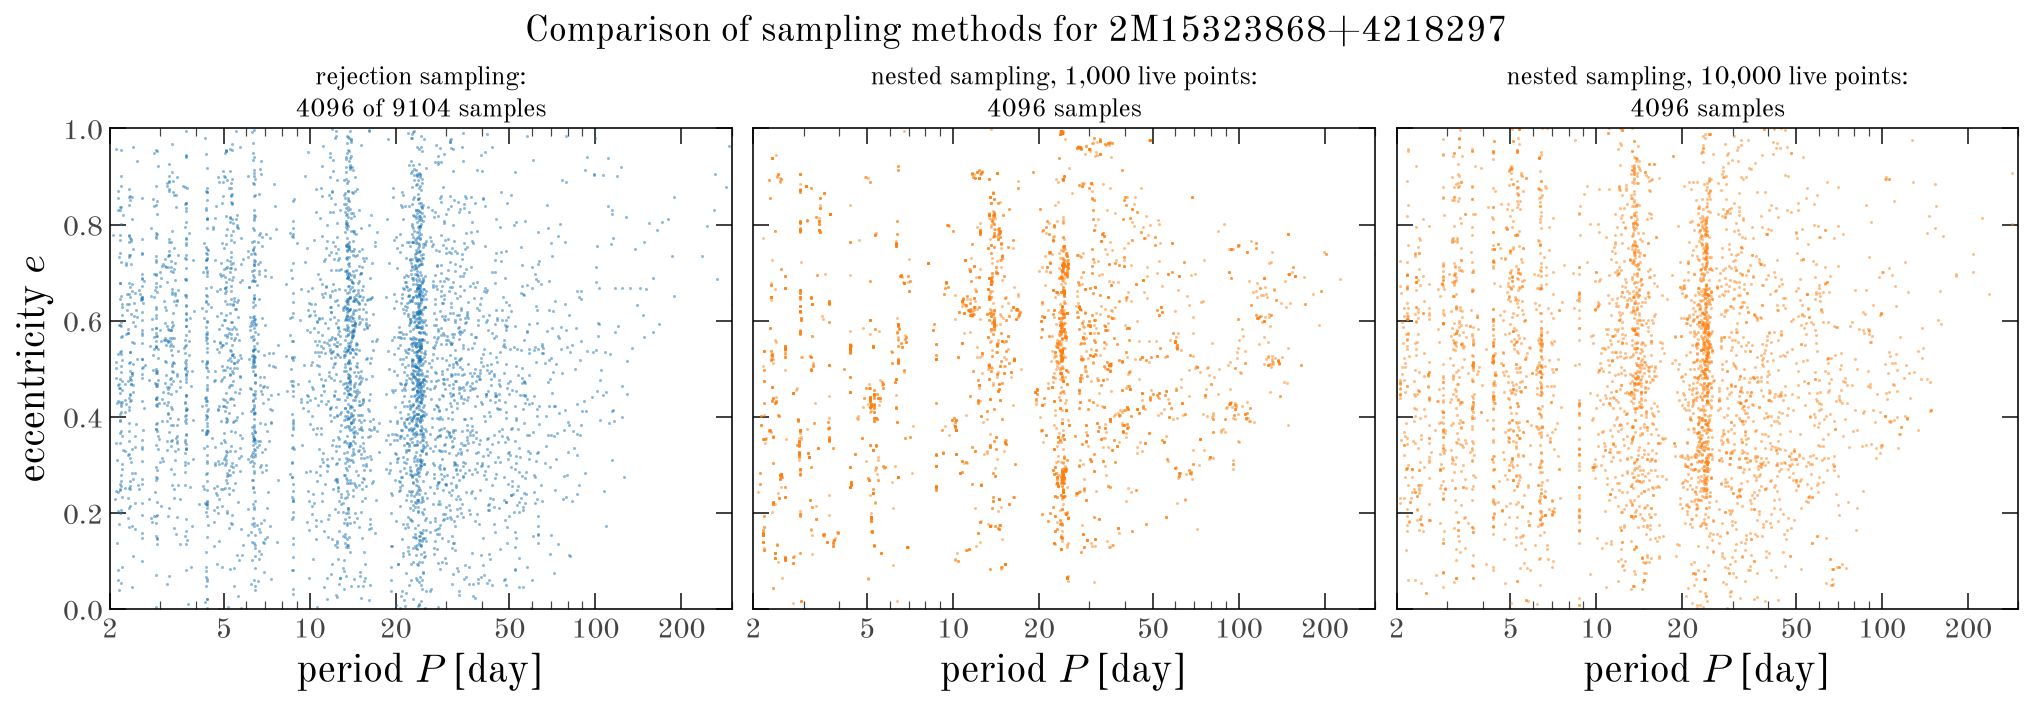

In [19]:
s = first_run[apogee_id]
idx = np.random.default_rng(0).choice(s.n_samples, 4096, replace=False)
panels = [
    (
        s["period"].to_value("day")[idx],
        s["eccentricity"].value[idx],
        "tab:blue",
        f"rejection sampling:\n4096 of {s.n_samples} samples",
    ),
    *[
        (
            x["posterior"]["period"],
            x["posterior"]["eccentricity"],
            "tab:orange",
            f"nested sampling, {n_live:,} live points:\n4096 samples",
        )
        for n_live, x in [(1000, ns[apogee_id][0]), (10_000, ns_10k[0])]
    ],
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), layout="constrained", sharey=True)
for ax, (P, e, color, title) in zip(axes, panels, strict=True):
    ax.plot(np.asarray(P), np.asarray(e), ".", ms=3, alpha=0.5, mew=0, color=color)
    ax.set_xscale("log")
    ax.set_xlim(2, 300)
    ax.set_xticks([2, 5, 10, 20, 50, 100, 200])
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("period $P$ [day]")
axes[0].set_ylabel("eccentricity $e$")
axes[0].set_ylim(0, 1)
fig.suptitle(f"Comparison of sampling methods for {apogee_id}", fontsize=18)
fig.savefig(figure_path / "cs3-nested-sampling.pdf")